#### Data Explore "SG Annual Car Population by Make From 2015 to 2025" from data.gov.sg
#### Take note that from 2022 onwards, the fuel type is started to split into catagories, petrol-electric/(plug-in) and diesel-electric/(plug-in)

In [11]:
import pandas as pd

df = pd.read_csv("/home/eric/NTU_DSAI/Project_2/data_lta/New_Cars_by_make_type_2025.csv")

print(df.tail())

      year   make importer_type                       fuel  \
6891  2025  VOLVO            PI                     Petrol   
6892  2025  VOLVO            PI            Petrol-Electric   
6893  2025  VOLVO            PI  Petrol-Electric (Plug-In)   
6894  2025  XPENG           AMD                   Electric   
6895  2025  ZEEKR           AMD                   Electric   

                    type  number  
6891  Coupe/ Convertible     NaN  
6892  Coupe/ Convertible     NaN  
6893  Coupe/ Convertible     NaN  
6894  Coupe/ Convertible     NaN  
6895  Coupe/ Convertible     NaN  


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6896 entries, 0 to 6895
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6896 non-null   int64  
 1   make           6896 non-null   object 
 2   importer_type  3390 non-null   object 
 3   fuel           6896 non-null   object 
 4   type           6896 non-null   object 
 5   number         2623 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 323.4+ KB


In [13]:
df.describe(include='object')

,make,importer_type,fuel,type
count,6896,3390,6896,6896
unique,93,2,8,7
top,MERCEDES BENZ,AMD,Petrol,Sports Utility Vehicle
freq,319,1920,3362,1260


In [14]:
df["year"]

0       2015
1       2015
2       2015
3       2015
4       2015
        ... 
6891    2025
6892    2025
6893    2025
6894    2025
6895    2025
Name: year, Length: 6896, dtype: int64

In [15]:
df["fuel"]

0                          Petrol
1                          Petrol
2                          Petrol
3                          Petrol
4                          Petrol
                  ...            
6891                       Petrol
6892              Petrol-Electric
6893    Petrol-Electric (Plug-In)
6894                     Electric
6895                     Electric
Name: fuel, Length: 6896, dtype: object

In [20]:
# Count all fuel type from YR2022 to YR2025

count_all = df["fuel"].value_counts()

print("=== Vehicle Count by Fuel Type (2022–2025) ===")
print(count_all)

=== Vehicle Count by Fuel Type (2022–2025) ===
Petrol                       3362
Electric                      966
Diesel                        846
Petrol-Electric               684
Others                        552
Petrol-Electric (Plug-In)     444
Diesel-Electric                36
Diesel-Electric (Plug-In)       6
Name: fuel, dtype: int64


In [21]:
# Take note for EV, it includes "Petrol-Electric (Plug-In)", "Electric" and "Diesel-Electric (Plug-In)" 
# The classification of fuel type starts from YR2022 onwards.

df["fuel"].unique()

array(['Petrol', 'Diesel', 'Others', 'Petrol-Electric',
       'Petrol-Electric (Plug-In)', 'Electric', 'Diesel-Electric',
       'Diesel-Electric (Plug-In)'], dtype=object)

In [22]:
# Check number of fuel_type: "Diesel-Electric (Plug-In)", not popular, basically it can be ignored.

ev_diesel_by_year = (
    df[df["fuel"] == "Diesel-Electric (Plug-In)"] 
    .groupby("year")["number"]
    .sum()
    .astype(int)
    .reset_index(name="count")
)

print(ev_diesel_by_year)

   year  count
0  2022      1


In [25]:
# Define EV and Non-EV in SG

ev_df = df[
    df["fuel"].isin([
        "Electric",
        "Petrol-Electric (Plug-In)",
        "Diesel-Electric (Plug-In)"
    ])
]

n_ev_df = df[
    df["fuel"].isin([
        "Petrol",
        "Diesel",
        "Petrol-Electric",
        "Diesel-Electric",
        "Petrol-CNG"
    ])
]

print(ev_df)
print(n_ev_df)
print()

      year     make importer_type                       fuel  \
2815  2022     AUDI           NaN  Petrol-Electric (Plug-In)   
2816  2022     AUDI           NaN                   Electric   
2822  2022   B.M.W.           NaN  Petrol-Electric (Plug-In)   
2823  2022   B.M.W.           NaN                   Electric   
2825  2022  BENTLEY           NaN  Petrol-Electric (Plug-In)   
...    ...      ...           ...                        ...   
6889  2025    VOLVO           AMD  Petrol-Electric (Plug-In)   
6890  2025    VOLVO           AMD                   Electric   
6893  2025    VOLVO            PI  Petrol-Electric (Plug-In)   
6894  2025    XPENG           AMD                   Electric   
6895  2025    ZEEKR           AMD                   Electric   

                    type  number  
2815           Hatchback     NaN  
2816           Hatchback    14.0  
2822           Hatchback     NaN  
2823           Hatchback     5.0  
2825           Hatchback     NaN  
...                  

In [26]:
# Count the no. of EV and Non-EV by year

ev_by_year = (
     ev_df   # fuel_type: Electric, Petrol/Diesel-Electric (Plug-In)
    .groupby("year")["number"]
    .sum()
    .astype(int)
    .reset_index(name="count")
)
n_ev_by_year = (
     n_ev_df   # fuel_type: Petrol/Petrol-Electric/Petrol-CNG, Diesel/Diesel-Electric
    .groupby("year")["number"]
    .sum()
    .astype(int)
    .reset_index(name="count")
)

ev_non_ev_by_year = pd.merge(
    ev_by_year,
    n_ev_by_year,
    on="year"
).fillna(0)

print("          EV    &  Non-EV:")
print(ev_non_ev_by_year)

          EV    &  Non-EV:
   year  count_x  count_y
0  2022     4046    26893
1  2023     5734    24491
2  2024    14658    28364
3  2025    24602    28076


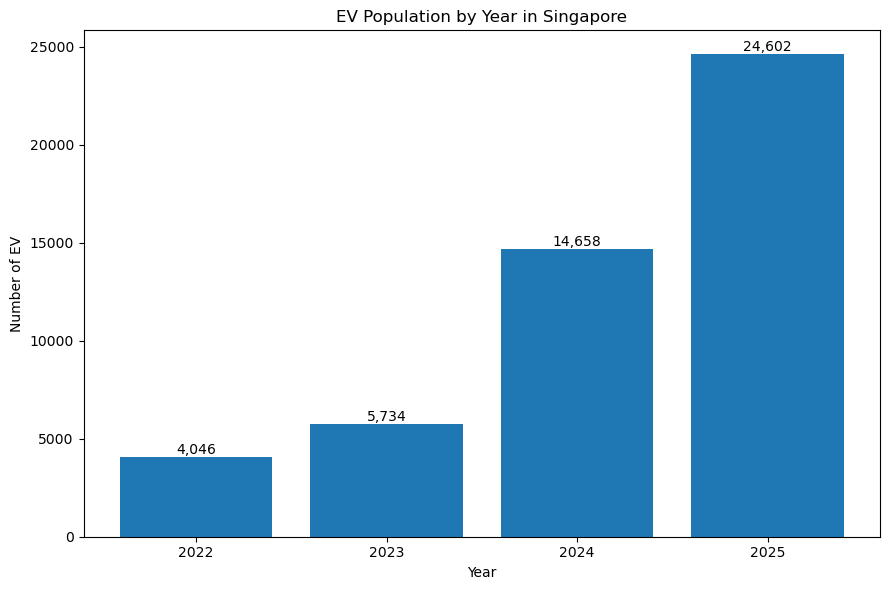

In [27]:
# Plot the bar chart

import matplotlib.pyplot as plt

ev = (
    ev_df
    .groupby("year")["number"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    ev["year"].astype(str),
    ev["number"]
)

plt.xlabel("Year")
plt.ylabel("Number of EV")
plt.title("EV Population by Year in Singapore")

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [29]:
# Find top 5 car make for EV

top5_ev_each_year = (
    df[df["fuel"].isin(["Electric", "Petrol-Electric (Plug-In)", "Diesel-Electric (Plug-In)"])]
    .groupby(["year", "make"])["number"]
    .sum()
    .reset_index(name="ev_vehicles")
    .sort_values(["year", "ev_vehicles"], ascending=[True, False])
    .groupby("year")
    .head(5)
)

print(top5_ev_each_year)

     year           make  ev_vehicles
23   2022          TESLA        875.0
4    2022            BYD        786.0
14   2022  MERCEDES BENZ        596.0
1    2022         B.M.W.        548.0
12   2022           M.G.        230.0
30   2023            BYD       1416.0
54   2023          TESLA        941.0
28   2023         B.M.W.        795.0
36   2023        HYUNDAI        694.0
45   2023  MERCEDES BENZ        649.0
61   2024            BYD       6191.0
92   2024          TESLA       2384.0
59   2024         B.M.W.       1642.0
70   2024        HYUNDAI        708.0
80   2024  MERCEDES BENZ        523.0
102  2025            BYD      11184.0
143  2025          TESLA       3476.0
100  2025         B.M.W.       1518.0
111  2025            GAC       1103.0
147  2025          XPENG        940.0


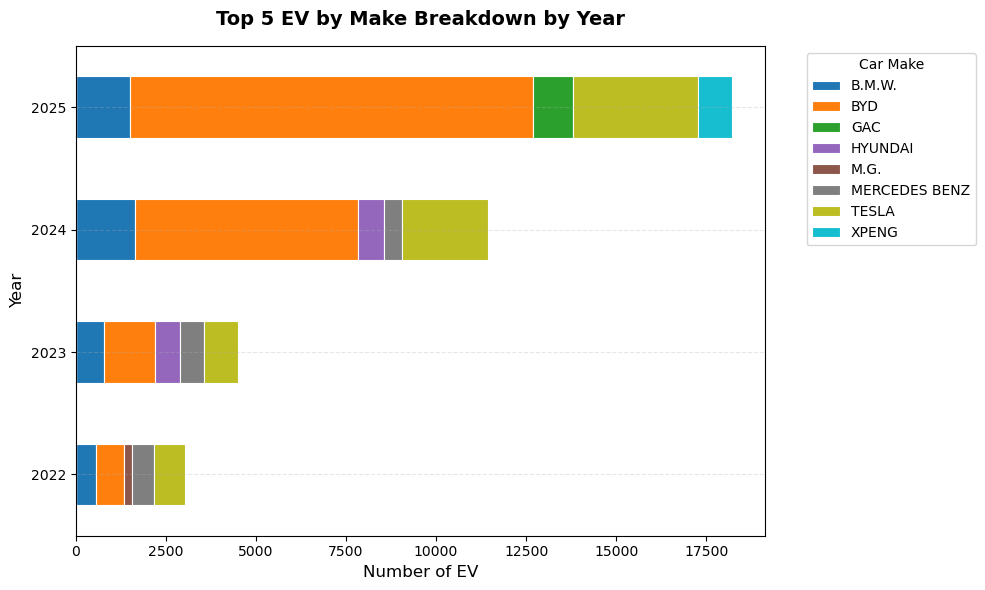

In [30]:
import matplotlib.pyplot as plt

# 1. Pivot the data so years are on the X-axis (index) and makes are stacked
pivot_df = top5_ev_each_year.pivot(index="year", columns="make", values="ev_vehicles")

# 2. Plot as a vertical stacked bar chart using a dark color palette ("magma")
ax = pivot_df.plot(
    kind="barh", 
    stacked=True, 
    figsize=(10, 6), 
    colormap="tab10",  # Modern dark theme palette
    edgecolor="white",  # Adds a crisp border between stacked segments
    linewidth=0.8
)

# Formatting the chart
plt.title("Top 5 EV by Make Breakdown by Year", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Number of EV", fontsize=12)
plt.ylabel("Year", fontsize=12)

# Keep the year labels vertical/upright
plt.xticks(rotation=0)  

# Place the dark-themed legend safely outside the graph area
plt.legend(title="Car Make", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

# Clean background lines
plt.grid(axis='y', linestyle="--", alpha=0.3)
plt.tight_layout()

plt.show()
